# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** AR RAHMAH KHULLATUL LUTFIYYAH
- **Email:** aaraffya@gmail.com
- **ID Dicoding:** arraalt

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks:** Olist adalah marketplace asal Brasil. Dataset berisi pesanan dari September 2016 sampai Oktober 2018. Data tahun 2016 dan September-Oktober 2018 sangat sedikit (lihat tahap *Assessing Data*), sehingga seluruh pertanyaan dibatasi pada periode **Januari 2017 - Agustus 2018** (20 bulan penuh). Semua nilai uang dalam **Real Brasil (R$)**, dan *revenue* didefinisikan sebagai total `price` barang (tidak termasuk ongkir) dari pesanan berstatus `delivered`.

**Pertanyaan 1:** ***Bagaimana tren jumlah pesanan dan total revenue bulanan dari pesanan berstatus delivered selama Januari 2017 - Agustus 2018, pada bulan apa terjadi puncak revenue, dan berapa pertumbuhan Month-over-Month (MoM) tertinggi?***

Keterangan:
* **Specific**: Tren pesanan & revenue bulanan, pesanan *delivered*
* **Measurable**: Jumlah pesanan, revenue (R$), growth MoM (%)
* **Action-Oriented**: Menentukan bulan untuk menambah stok & kampanye
* **Relevant**: Perencanaan penjualan & inventori marketplace
* **Time-bound**: Jan 2017 - Agu 2018

**Pertanyaan 2:** ***Kategori produk apa saja yang menjadi 10 besar penyumbang *revenue* selama Januari 2017 - Agustus 2018, dan berapa rata-rata *review score* masing-masing kategori dibandingkan rata-rata keseluruhan, sehingga tim dapat menentukan kategori yang diprioritaskan untuk promosi dan kategori yang perlu perbaikan kualitas/layanan?***

Keterangan:
* **Specific**: Top 10 kategori produk menurut revenue + review score
* **Measurable**: Revenue (R$), rata-rata review score (1-5)
* **Action-Oriented**: Menentukan kategori untuk promosi vs perbaikan kualitas
* **Relevant**: Strategi merchandising dan kualitas penjual
* **Time-bound**: Jan 2017 - Agu 2018

**Pertanyaan 3:** ***Seberapa besar keterlambatan pengiriman (tanggal pesanan diterima pelanggan melewati tanggal estimasi) menurunkan rata-rata *review score*, dan di *state* mana persentase pesanan terlambat paling tinggi selama Januari 2017 - Agustus 2018?***

Keterangan:
* **Specific**: Dampak keterlambatan ke review score + *state* paling sering terlambat
* **Measurable**: Selisih rata-rata review score, % pesanan terlambat
* **Action-Oriented**: Menentukan wilayah yang perlu perbaikan logistik/estimasi
* **Relevant**: Kepuasan pelanggan ditentukan oleh kualitas pengiriman
* **Time-bound**: Jan 2017 - Agu 2018

## Import Semua Packages/Library yang Digunakan

Library yang digunakan:
- `pandas` & `numpy`: manipulasi dan agregasi data.
- `matplotlib` & `seaborn`: visualisasi statis.
- `folium`: peta interaktif untuk analisis geospasial.

Warna visualisasi mengikuti prinsip desain: **biru** untuk data utama, **oranye** hanya untuk sorotan/peringatan (misalnya puncak atau di bawah rata-rata), dan **abu-abu** untuk konteks.

In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import folium

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

# Palet warna: biru = data utama, oranye = sorotan/peringatan, abu = konteks
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b9b8b2'
INK, INK_2 = '#0b0b0b', '#52514e'

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ebeae6', 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2,
})

# Lokasi folder data (otomatis menyesuaikan jika dijalankan di Colab)
# Lokasi folder data dari Google Drive
DATA_DIR = '/content/drive/MyDrive/data'
print('Folder data:', DATA_DIR)

Folder data: /content/drive/MyDrive/data


## Data Wrangling

### Gathering Data

Pada tahap ini seluruh tabel dimuat ke dalam *DataFrame*. Dataset terdiri dari beberapa tabel relasional yang dihubungkan lewat `order_id`, `customer_id`, `product_id`, dan `seller_id`.

> **Catatan:** `geolocation_dataset.csv` berisi koordinat (lintang/bujur) tiap kode pos. Tabel ini dipakai pada tahap *Analisis Lanjutan* untuk peta per kota dan perhitungan jarak antara penjual dan pelanggan. Berkas lengkapnya sekitar 1 juta baris (>30 MB); notebook ini otomatis membaca `geolocation_dataset.csv`

#### Load df customers, orders, dan order items

In [41]:
customers_df = pd.read_csv(f'{DATA_DIR}/customers_dataset.csv')
orders_df = pd.read_csv(f'{DATA_DIR}/orders_dataset.csv')
order_items_df = pd.read_csv(f'{DATA_DIR}/order_items_dataset.csv')

display(customers_df.head(3))
display(orders_df.head(3))
display(order_items_df.head(3))

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


#### Load df products, category translation, dan sellers

In [42]:
products_df = pd.read_csv(f'{DATA_DIR}/products_dataset.csv')
category_translation_df = pd.read_csv(f'{DATA_DIR}/product_category_name_translation.csv', encoding='utf-8-sig')
sellers_df = pd.read_csv(f'{DATA_DIR}/sellers_dataset.csv')

display(products_df.head(3))
display(category_translation_df.head(3))
display(sellers_df.head(3))

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


Load df payments, reviews, dan geolocation

In [43]:
order_payments_df = pd.read_csv(f'{DATA_DIR}/order_payments_dataset.csv')
order_reviews_df = pd.read_csv(f'{DATA_DIR}/order_reviews_dataset.csv')

display(order_payments_df.head(3))
display(order_reviews_df.head(3))

# Berkas lengkap (+/- 1 juta baris) atau versi ringkas (<30 MB): pakai yang tersedia
geo_path = next(p for p in [f'{DATA_DIR}/geolocation_dataset.csv', f'{DATA_DIR}/geolocation_dataset_under30mb.csv']
                if os.path.exists(p))
try:
    geolocation_df = pd.read_csv(geo_path)
except UnicodeDecodeError:
    geolocation_df = pd.read_csv(geo_path, encoding='latin-1')
print('Berkas geolocation:', geo_path)
display(geolocation_df.head(3))

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


Berkas geolocation: /content/drive/MyDrive/data/geolocation_dataset.csv


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP


Ringkasan ukuran seluruh tabel

In [44]:
datasets = {
    'customers': customers_df, 'orders': orders_df, 'order_items': order_items_df,
    'order_payments': order_payments_df, 'order_reviews': order_reviews_df,
    'products': products_df, 'category_translation': category_translation_df, 'sellers': sellers_df,
    'geolocation': geolocation_df,
}
pd.DataFrame({
    'jumlah_baris': {k: v.shape[0] for k, v in datasets.items()},
    'jumlah_kolom': {k: v.shape[1] for k, v in datasets.items()},
})

,jumlah_baris,jumlah_kolom
customers,99441,5
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
category_translation,71,2
sellers,3095,4
geolocation,1000163,5


**Insight:**
- Dataset terdiri dari 9 tabel relasional. Tabel terbesar adalah `geolocation` (1.000.163 baris), `order_items` (112.650 baris), dan `order_payments` (103.886 baris), sedangkan `orders` dan `customers` masing-masing 99.441 baris (satu pesanan = satu `customer_id`).
- Rentang waktu `orders` adalah September 2016 sampai Oktober 2018.
- `order_reviews` hanya 99.224 baris, lebih sedikit dari jumlah pesanan, jadi tidak semua pesanan memiliki review.
- `geolocation` menyimpan koordinat untuk tiap kode pos, sehingga bisa digabung ke `customers` dan `sellers` lewat kode pos masing-masing. Tabel lain digabung lewat `order_id`, `customer_id`, `product_id`, dan `seller_id`.

### Assessing Data

Tahap ini memeriksa kualitas data: tipe data, *missing value*, duplikasi, nilai tidak valid/tidak konsisten, *outlier*, dan cakupan periode. Hasil temuan dirangkum pada bagian **Steps to Take** sebagai dasar tahap *Cleaning Data*.

#### Identifying tipe data dan missing value

In [45]:
def cek_missing(df, nama):
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f'== {nama} ({len(df):,} baris)')
    if len(miss):
        print(miss.to_frame('jumlah_missing').assign(persen=lambda x: (x.jumlah_missing / len(df) * 100).round(2)))
    else:
        print('Tidak ada missing value')
    print()

for nama, df in datasets.items():
    cek_missing(df, nama)

print('Tipe data kolom tanggal pada orders (masih string, bukan datetime):')
print(orders_df.dtypes[orders_df.columns.str.contains('timestamp|_at$|_date$')])

== customers (99,441 baris)
Tidak ada missing value

== orders (99,441 baris)
                               jumlah_missing  persen
order_approved_at                         160    0.16
order_delivered_carrier_date             1783    1.79
order_delivered_customer_date            2965    2.98

== order_items (112,650 baris)
Tidak ada missing value

== order_payments (103,886 baris)
Tidak ada missing value

== order_reviews (99,224 baris)
                        jumlah_missing  persen
review_comment_title             87656   88.34
review_comment_message           58247   58.70

== products (32,951 baris)
                            jumlah_missing  persen
product_category_name                  610    1.85
product_name_lenght                    610    1.85
product_description_lenght             610    1.85
product_photos_qty                     610    1.85
product_weight_g                         2    0.01
product_length_cm                        2    0.01
product_height_cm               

#### Identifying duplicate data

In [46]:
print('Baris duplikat penuh per tabel:')
for nama, df in datasets.items():
    print(f'  {nama:22s}: {df.duplicated().sum()}')

print()
print('review_id yang muncul lebih dari sekali :', order_reviews_df['review_id'].duplicated().sum())
print('order_id dengan lebih dari satu review   :', order_reviews_df['order_id'].duplicated().sum())

contoh = order_reviews_df[order_reviews_df['order_id'].duplicated(keep=False)].sort_values('order_id').head(4)
contoh[['order_id', 'review_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']]

Baris duplikat penuh per tabel:
  customers             : 0
  orders                : 0
  order_items           : 0
  order_payments        : 0
  order_reviews         : 0
  products              : 0
  category_translation  : 0
  sellers               : 0
  geolocation           : 261831

review_id yang muncul lebih dari sekali : 814
order_id dengan lebih dari satu review   : 551


,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04 00:00:00,2018-03-05 17:02:00


#### Identifying invalid/incosistent value

In [47]:
tgl_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
            'order_delivered_customer_date', 'order_estimated_delivery_date']
orders_chk = orders_df.copy()
for c in tgl_cols:
    orders_chk[c] = pd.to_datetime(orders_chk[c])

print('Distribusi status pesanan:')
print(orders_chk['order_status'].value_counts().to_string())
print()
print('Status delivered tetapi tanggal diterima pelanggan kosong :',
      ((orders_chk.order_status == 'delivered') & orders_chk.order_delivered_customer_date.isna()).sum())
print('Status BUKAN delivered tetapi punya tanggal diterima       :',
      ((orders_chk.order_status != 'delivered') & orders_chk.order_delivered_customer_date.notna()).sum())
print('Tanggal kirim ke kurir lebih awal dari tanggal pembelian   :',
      (orders_chk.order_delivered_carrier_date < orders_chk.order_purchase_timestamp).sum())
print('Tanggal diterima lebih awal dari tanggal pembelian         :',
      (orders_chk.order_delivered_customer_date < orders_chk.order_purchase_timestamp).sum())

print()
kategori_produk = set(products_df['product_category_name'].dropna().unique())
kategori_terjemahan = set(category_translation_df['product_category_name'])
print('Kategori produk yang tidak ada di tabel terjemahan:', kategori_produk - kategori_terjemahan)
print('Terjemahan dengan salah ketik     :', [k for k in category_translation_df['product_category_name_english']
                                              if 'costruction' in k or 'fashio_' in k or 'confort' in k])

print()
print('Pembayaran dengan payment_type "not_defined":', (order_payments_df.payment_type == 'not_defined').sum())
print('Pembayaran dengan payment_value = 0         :', (order_payments_df.payment_value == 0).sum())
print('Produk dengan berat 0 gram                  :', (products_df.product_weight_g == 0).sum())

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Status delivered tetapi tanggal diterima pelanggan kosong : 8
Status BUKAN delivered tetapi punya tanggal diterima       : 6
Tanggal kirim ke kurir lebih awal dari tanggal pembelian   : 166
Tanggal diterima lebih awal dari tanggal pembelian         : 0

Kategori produk yang tidak ada di tabel terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
Terjemahan dengan salah ketik     : ['costruction_tools_garden', 'home_confort', 'costruction_tools_tools', 'fashio_female_clothing']

Pembayaran dengan payment_type "not_defined": 3
Pembayaran dengan payment_value = 0         : 9
Produk dengan berat 0 gram                  : 4


#### Identifying outlier

In [48]:
def ringkas_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    return pd.Series({'median': s.median(), 'q3': q3, 'batas_atas_IQR': batas,
                      'jumlah_outlier': (s > batas).sum(), 'persen_outlier': (s > batas).mean() * 100,
                      'nilai_maks': s.max()})

pd.DataFrame({
    'price': ringkas_outlier(order_items_df['price']),
    'freight_value': ringkas_outlier(order_items_df['freight_value']),
    'product_weight_g': ringkas_outlier(products_df['product_weight_g'].dropna()),
}).T.round(2)

,median,q3,batas_atas_IQR,jumlah_outlier,persen_outlier,nilai_maks
price,74.99,134.90,277.40,8427.0,7.48,6735.00
freight_value,16.26,21.15,33.25,11613.0,10.31,409.68
product_weight_g,700.00,1900.00,4300.00,4551.0,13.81,40425.00


#### Identifying masalah pada data geolocation

In [49]:
zip_unik = geolocation_df['geolocation_zip_code_prefix'].nunique()
print('Baris geolocation                    :', f'{len(geolocation_df):,}')
print('Kode pos (prefix) unik               :', f'{zip_unik:,}')
print('Rata-rata titik koordinat per kode pos:', round(len(geolocation_df) / zip_unik, 1))
print('Baris duplikat penuh                 :', f'{geolocation_df.duplicated().sum():,}')

# Batas kasar wilayah daratan Brasil (lintang -33.8 s.d. 5.3, bujur -73.9 s.d. -34.7)
di_dalam = (geolocation_df['geolocation_lat'].between(-33.8, 5.3)
            & geolocation_df['geolocation_lng'].between(-73.9, -34.7))
print('Titik di luar wilayah Brasil         :', (~di_dalam).sum())
display(geolocation_df[~di_dalam].head(3))

nama_kota = geolocation_df['geolocation_city']
print('Nama kota unik                       :', nama_kota.nunique())
print('Nama kota yang memakai aksen (mis. sao paulo vs são paulo):',
      nama_kota[~nama_kota.astype(str).map(str.isascii)].nunique())
print()
print('% pelanggan dengan kode pos tidak ada di geolocation:',
      round((~customers_df['customer_zip_code_prefix'].isin(geolocation_df['geolocation_zip_code_prefix'])).mean() * 100, 2))
print('% penjual   dengan kode pos tidak ada di geolocation:',
      round((~sellers_df['seller_zip_code_prefix'].isin(geolocation_df['geolocation_zip_code_prefix'])).mean() * 100, 2))

Baris geolocation                    : 1,000,163
Kode pos (prefix) unik               : 19,015
Rata-rata titik koordinat per kode pos: 52.6
Baris duplikat penuh                 : 261,831
Titik di luar wilayah Brasil         : 42


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ


Nama kota unik                       : 8011
Nama kota yang memakai aksen (mis. sao paulo vs são paulo): 2085

% pelanggan dengan kode pos tidak ada di geolocation: 0.28
% penjual   dengan kode pos tidak ada di geolocation: 0.23


#### Identifying cakupan periode data

In [50]:
pesanan_per_bulan = orders_chk.groupby(orders_chk['order_purchase_timestamp'].dt.to_period('M')).size()
print(pesanan_per_bulan.to_string())

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


**Steps to Take:**
- **Tipe data tanggal salah:** ubah seluruh kolom tanggal pada `orders`, `order_items`, dan `order_reviews` menjadi `datetime`.
- **Missing value pada tanggal pesanan:** pesanan non-*delivered* wajar tidak punya tanggal diterima. Analisis hanya memakai pesanan `delivered` dan membuang pesanan *delivered* yang tanggal diterimanya kosong.
- **Data tidak konsisten:** status non-*delivered* yang memiliki tanggal diterima terselesaikan dengan menyaring status `delivered`. Tanggal kirim ke kurir yang lebih awal dari tanggal pembelian diubah menjadi `NaT` (tidak valid).
- **Duplikasi review:** beberapa `order_id` punya lebih dari satu review. Simpan **review terbaru** per pesanan agar tidak menggandakan pesanan saat digabung.
- **Kategori tanpa terjemahan / salah ketik:** lengkapi terjemahan secara manual, perbaiki salah ketik, dan isi kategori kosong dengan `unknown`.
- **Pembayaran tidak valid:** buang `payment_type = not_defined`.
- **Outlier harga/ongkir/berat:** nilai ekstrem terlihat wajar secara bisnis (barang mahal atau berat), sehingga **dipertahankan** agar revenue tidak terpotong.
- **Cakupan periode tidak merata:** 2016 dan September-Oktober 2018 hanya berisi sedikit pesanan, sehingga analisis dibatasi pada **Januari 2017 - Agustus 2018**.
- **Data geolocation:** hapus baris duplikat, buang titik di luar wilayah Brasil, lalu ringkas banyak titik pada satu kode pos menjadi **satu koordinat per kode pos** (median) agar penggabungan dengan pelanggan/penjual tidak menggandakan baris. Kode pos yang tidak ditemukan dibiarkan kosong (tidak ditebak).

**Insight:**
- Kolom tanggal pada `orders`, `order_items`, dan `order_reviews` masih bertipe string sehingga belum bisa dihitung selisih harinya.
- *Missing value* pada `orders`: `order_delivered_customer_date` kosong 2.965 baris (2,98%), `order_delivered_carrier_date` 1.783 baris (1,79%), dan `order_approved_at` 160 baris (0,16%). Pada `order_reviews`, judul komentar kosong 88,34% dan isi komentar kosong 58,70% (kolom ini tidak dipakai dalam analisis). Pada `products`, 610 produk (1,85%) tidak memiliki kategori, nama, deskripsi, dan jumlah foto, serta 2 produk tidak memiliki ukuran/berat.
- Tabel selain `geolocation` tidak punya baris duplikat penuh. Namun 551 `order_id` memiliki lebih dari satu review dan 814 `review_id` muncul lebih dari sekali. Jika digabung tanpa dibersihkan, satu pesanan akan terhitung ganda.
- Ketidakkonsistenan: 8 pesanan berstatus *delivered* tanpa tanggal diterima, 6 pesanan non-*delivered* yang justru punya tanggal diterima, 166 tanggal kirim ke kurir yang lebih awal dari tanggal pembelian, 2 kategori tanpa terjemahan (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`), dan 4 salah ketik pada nama kategori. Ada 3 pembayaran `not_defined`, 9 pembayaran bernilai 0, dan 4 produk berberat 0 gram.
- *Outlier*: 7,48% harga barang berada di atas batas IQR (maksimum R$ 6.735). Nilai ini masuk akal secara bisnis (barang mahal) sehingga dipertahankan.
- Cakupan periode tidak merata: tahun 2016 hanya 329 pesanan (4 + 324 + 1) dan September-Oktober 2018 hanya 20 pesanan (16 + 4), sedangkan Januari 2017 - Agustus 2018 berisi 800 hingga 7.544 pesanan per bulan.
- Data geolocation bermasalah paling besar: dari 1.000.163 baris, **261.831 baris (26,2%) adalah duplikat penuh**, dan satu kode pos (dari 19.015 kode pos unik) rata-rata punya 52,6 titik koordinat berbeda. Ada 42 titik berkoordinat di luar wilayah Brasil (misalnya lintang 28° atau 41° untuk kota yang tercatat di SP dan RJ, dan titik di bujur -58,7 yang berada di Argentina). Selain itu ada 8.011 nama kota unik, dengan 2.085 di antaranya ditulis memakai aksen sehingga berbeda dari penulisan tanpa aksen. Hanya 0,28% pelanggan dan 0,23% penjual yang kode posnya tidak ada di tabel ini, jadi cakupannya hampir penuh.

### Cleaning Data

#### Fixing tipe data tanggal

In [51]:
for c in tgl_cols:
    orders_df[c] = pd.to_datetime(orders_df[c])

order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

orders_df[tgl_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing tanggal tidak valid, status pesanan, dan cakupan periode

In [52]:
# Tanggal kirim ke kurir yang lebih awal dari tanggal pembelian dianggap tidak valid
tidak_valid = orders_df['order_delivered_carrier_date'] < orders_df['order_purchase_timestamp']
print('Tanggal kurir tidak valid yang dikosongkan:', tidak_valid.sum())
orders_df.loc[tidak_valid, 'order_delivered_carrier_date'] = pd.NaT

# Saring pesanan: delivered + tanggal diterima terisi + periode Jan 2017 - Agu 2018
awal, akhir = pd.Timestamp('2017-01-01'), pd.Timestamp('2018-08-31 23:59:59')
n0 = len(orders_df)
orders_valid = orders_df[orders_df['order_status'] == 'delivered']
n1 = len(orders_valid)
orders_valid = orders_valid[orders_valid['order_delivered_customer_date'].notna()]
n2 = len(orders_valid)
orders_valid = orders_valid[orders_valid['order_purchase_timestamp'].between(awal, akhir)].copy()
n3 = len(orders_valid)

print(f'Seluruh pesanan                          : {n0:,}')
print(f'Setelah filter status delivered          : {n1:,}  (-{n0 - n1:,})')
print(f'Setelah buang tanggal diterima kosong    : {n2:,}  (-{n1 - n2:,})')
print(f'Setelah batasi periode Jan 2017-Agu 2018 : {n3:,}  (-{n2 - n3:,})')

Tanggal kurir tidak valid yang dikosongkan: 166
Seluruh pesanan                          : 99,441
Setelah filter status delivered          : 96,478  (-2,963)
Setelah buang tanggal diterima kosong    : 96,470  (-8)
Setelah batasi periode Jan 2017-Agu 2018 : 96,203  (-267)


#### Fixing duplikasi review

In [53]:
# Simpan review paling akhir (berdasarkan waktu jawaban) untuk setiap pesanan
reviews_clean = (order_reviews_df
                 .sort_values(['order_id', 'review_answer_timestamp'])
                 .drop_duplicates('order_id', keep='last'))

print('Sebelum:', len(order_reviews_df), '| Sesudah:', len(reviews_clean))
print('order_id duplikat sesudah dibersihkan:', reviews_clean['order_id'].duplicated().sum())

Sebelum: 99224 | Sesudah: 98673
order_id duplikat sesudah dibersihkan: 0


#### Fixing nama kategori produk (terjemahan, salah ketik, missing)

In [54]:
terjemahan = dict(zip(category_translation_df['product_category_name'],
                      category_translation_df['product_category_name_english']))
# Dua kategori yang belum ada di tabel terjemahan
terjemahan.update({
    'pc_gamer': 'pc_gamer',
    'portateis_cozinha_e_preparadores_de_alimentos': 'portable_kitchen_food_preparers',
})
# Perbaikan salah ketik pada tabel terjemahan bawaan
salah_ketik = {
    'costruction_tools_garden': 'construction_tools_garden',
    'costruction_tools_tools': 'construction_tools_tools',
    'fashio_female_clothing': 'fashion_female_clothing',
    'home_confort': 'home_comfort',
}

products_clean = products_df.copy()
products_clean['product_category_name_english'] = (products_clean['product_category_name']
                                                   .map(terjemahan)
                                                   .replace(salah_ketik)
                                                   .fillna('unknown'))

print('Produk dengan kategori unknown:', (products_clean['product_category_name_english'] == 'unknown').sum())
print('Jumlah kategori unik            :', products_clean['product_category_name_english'].nunique())

# Pembayaran tidak valid
payments_clean = order_payments_df[order_payments_df['payment_type'] != 'not_defined'].copy()
print('Pembayaran setelah buang not_defined:', len(payments_clean))

Produk dengan kategori unknown: 610
Jumlah kategori unik            : 74
Pembayaran setelah buang not_defined: 103883


#### Fixing data geolocation

In [55]:
n_awal = len(geolocation_df)
zip_awal = geolocation_df['geolocation_zip_code_prefix'].nunique()

# 1) Buang baris duplikat penuh
geo_clean = geolocation_df.drop_duplicates()
n_dup = n_awal - len(geo_clean)

# 2) Buang titik di luar wilayah Brasil
di_dalam = (geo_clean['geolocation_lat'].between(-33.8, 5.3)
            & geo_clean['geolocation_lng'].between(-73.9, -34.7))
n_luar = (~di_dalam).sum()
geo_clean = geo_clean[di_dalam]

# 3) Satu kode pos = satu koordinat (median lebih tahan terhadap titik pencilan dibanding rata-rata)
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix')
           .agg(zip_lat=('geolocation_lat', 'median'), zip_lng=('geolocation_lng', 'median'))
           .reset_index())

print(f'Baris awal                          : {n_awal:,}')
print(f'Duplikat dibuang                    : {n_dup:,}')
print(f'Di luar Brasil dibuang (setelah dedup): {n_luar:,}')
print(f'Baris geolocation bersih            : {len(geo_clean):,}')
print(f'Kode pos awal -> akhir              : {zip_awal:,} -> {len(geo_zip):,} (hilang: {zip_awal - len(geo_zip)})')
print(f'Satu baris per kode pos             : {geo_zip["geolocation_zip_code_prefix"].is_unique}')

# Jarak garis lurus (rumus haversine) antara dua titik koordinat, dalam kilometer
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Uji cepat: Sao Paulo -> Rio de Janeiro seharusnya sekitar 360 km
print('Uji haversine SP-RJ (km):', round(float(haversine_km(-23.55, -46.63, -22.91, -43.17)), 0))

Baris awal                          : 1,000,163
Duplikat dibuang                    : 261,831
Di luar Brasil dibuang (setelah dedup): 33
Baris geolocation bersih            : 738,299
Kode pos awal -> akhir              : 19,015 -> 19,010 (hilang: 5)
Satu baris per kode pos             : True
Uji haversine SP-RJ (km): 361.0


#### Menggabungkan seluruh tabel menjadi satu *master dataframe*

Tabel digabung pada level **item pesanan** (satu baris = satu item dalam pesanan). Kolom turunan yang dibuat:
- `delivery_days`: lama pengiriman (hari) dari pembelian sampai diterima pelanggan.
- `delay_days`: selisih hari antara tanggal diterima dan tanggal estimasi (**positif = terlambat**).
- `is_late`: `True` jika `delay_days > 0`.
- `customer_lat`, `customer_lng`, `seller_lat`, `seller_lng`: koordinat dari kode pos pelanggan dan penjual.
- `distance_km`: jarak garis lurus penjual ke pelanggan (km).

In [56]:
all_df = (orders_valid
          .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state', 'customer_zip_code_prefix']],
                 on='customer_id', how='left')
          .merge(order_items_df[['order_id', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value']],
                 on='order_id', how='inner')
          .merge(products_clean[['product_id', 'product_category_name_english']], on='product_id', how='left')
          .merge(sellers_df[['seller_id', 'seller_state', 'seller_zip_code_prefix']], on='seller_id', how='left')
          .merge(geo_zip.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                         'zip_lat': 'customer_lat', 'zip_lng': 'customer_lng'}),
                 on='customer_zip_code_prefix', how='left')
          .merge(geo_zip.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                         'zip_lat': 'seller_lat', 'zip_lng': 'seller_lng'}),
                 on='seller_zip_code_prefix', how='left')
          .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left'))

all_df['product_category_name_english'] = all_df['product_category_name_english'].fillna('unknown')
all_df['order_month'] = all_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

all_df['delivery_days'] = ((all_df['order_delivered_customer_date'] - all_df['order_purchase_timestamp'])
                           .dt.total_seconds() / 86400).round(2)
all_df['delay_days'] = (all_df['order_delivered_customer_date'].dt.normalize()
                        - all_df['order_estimated_delivery_date'].dt.normalize()).dt.days
all_df['is_late'] = all_df['delay_days'] > 0

# Binning: kelompok ketepatan pengiriman
bins = [-np.inf, -8, -1, 0, 3, 7, np.inf]
labels = ['Lebih cepat >7 hari', 'Lebih cepat 1-7 hari', 'Tepat di hari estimasi',
          'Telat 1-3 hari', 'Telat 4-7 hari', 'Telat >7 hari']
all_df['delay_bucket'] = pd.cut(all_df['delay_days'], bins=bins, labels=labels)

# Jarak penjual ke pelanggan (km)
all_df['distance_km'] = haversine_km(all_df['seller_lat'], all_df['seller_lng'],
                                     all_df['customer_lat'], all_df['customer_lng'])

# Validasi akhir
n_item_valid = order_items_df['order_id'].isin(orders_valid['order_id']).sum()
print('Baris master df      :', len(all_df), '| item pesanan valid:', n_item_valid)
print('Pesanan unik         :', all_df['order_id'].nunique())
print('Missing review_score :', all_df['review_score'].isna().sum(), 'baris')
print('Tanpa koordinat pelanggan / penjual / jarak:', all_df['customer_lat'].isna().sum(), '/',
      all_df['seller_lat'].isna().sum(), '/', all_df['distance_km'].isna().sum(), 'baris')
sisa_missing = all_df.drop(columns=['review_score']).isna().sum()
print('Sisa missing (selain review_score):')
print(sisa_missing[sisa_missing > 0].to_string())
all_df.head()

Baris master df      : 109872 | item pesanan valid: 109872
Pesanan unik         : 96203
Missing review_score : 823 baris
Tanpa koordinat pelanggan / penjual / jarak: 289 / 249 / 537 baris
Sisa missing (selain review_score):
order_approved_at                15
order_delivered_carrier_date    187
customer_lat                    289
customer_lng                    289
seller_lat                      249
seller_lng                      249
distance_km                     537


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,customer_zip_code_prefix,order_item_id,product_id,seller_id,...,freight_value,product_category_name_english,seller_state,seller_zip_code_prefix,customer_lat,customer_lng,seller_lat,seller_lng,review_score,order_month,delivery_days,delay_days,is_late,delay_bucket,distance_km
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,3149,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,...,8.72,housewares,SP,9350,-23.575816,-46.587303,-23.681135,-46.444490,4.0,2017-10,8.44,-8,False,Lebih cepat >7 hari,18.676576
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,47813,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,...,22.76,perfumery,SP,31570,-12.126533,-45.008244,-19.807199,-43.981058,4.0,2018-07,13.78,-6,False,Lebih cepat 1-7 hari,861.068703
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,75265,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,...,19.22,auto,SP,14840,-16.744472,-48.514624,-21.363908,-48.228772,5.0,2018-08,9.39,-18,False,Lebih cepat >7 hari,514.535098
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,59296,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,...,27.20,pet_shop,MG,31842,-5.773971,-35.273838,-19.836541,-43.921911,5.0,2017-11,13.21,-13,False,Lebih cepat >7 hari,1821.871635
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,9195,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,...,8.72,stationery,SP,8752,-23.675471,-46.514788,-23.543747,-46.262070,5.0,2018-02,2.87,-10,False,Lebih cepat >7 hari,29.623195


#### Menyimpan data bersih untuk dashboard

In [57]:
kolom_dashboard = ['order_id', 'customer_unique_id', 'customer_state', 'customer_city', 'seller_state',
                   'customer_lat', 'customer_lng', 'distance_km',
                   'order_purchase_timestamp', 'product_category_name_english',
                   'price', 'freight_value', 'review_score', 'delivery_days', 'delay_days', 'is_late']
os.makedirs('dashboard', exist_ok=True)
all_df[kolom_dashboard].round({'customer_lat': 4, 'customer_lng': 4, 'distance_km': 1}).to_csv('dashboard/main_data.csv', index=False)

print('main_data.csv tersimpan:', all_df[kolom_dashboard].shape)
print('Ukuran file (MB):', round(os.path.getsize('dashboard/main_data.csv') / 1e6, 1))

main_data.csv tersimpan: (109872, 16)
Ukuran file (MB): 18.8


**Insight:**
- Dari 99.441 pesanan, tersisa **96.203 pesanan (96,7%)** untuk analisis. Yang dibuang: 2.963 pesanan non-*delivered*, 8 pesanan tanpa tanggal diterima, dan 267 pesanan di luar periode Jan 2017 - Agu 2018.
- Dedup review menyisakan 98.673 review unik (satu per pesanan), sehingga penggabungan tidak menggandakan pesanan.
- Master dataframe berisi 109.872 baris item dari 96.203 pesanan. Sebanyak 823 baris (sekitar 0,7%) tidak punya `review_score`; baris ini hanya dikecualikan pada analisis review dan tetap dipakai untuk analisis revenue. Sisa *missing* lainnya hanya pada kolom tanggal persetujuan (15 baris) dan serah ke kurir (187 baris) yang tidak dipakai dalam analisis.
- Geolocation dibersihkan dari 1.000.163 baris menjadi 738.299 baris: **261.831 baris duplikat** dan 33 titik di luar wilayah Brasil (setelah deduplikasi) dibuang. Banyak titik per kode pos kemudian diringkas menjadi **satu koordinat (median) per kode pos**, sehingga tersisa 19.010 kode pos (5 dari 19.015 kode pos hilang karena seluruh titiknya berada di luar Brasil). Penggabungan ke master dataframe tidak menambah baris (tetap 109.872). Koordinat pelanggan kosong pada 289 baris, koordinat penjual pada 249 baris, dan jarak tidak dapat dihitung pada 537 baris (sekitar 0,5%); baris ini hanya dikecualikan dari analisis jarak. Rumus haversine diuji pada Sao Paulo-Rio de Janeiro dan menghasilkan 361 km, sesuai jarak sebenarnya (sekitar 360 km).
- Setelah pembersihan terdapat 74 kategori (termasuk `unknown` untuk 610 produk tanpa kategori). Data bersih (16 kolom, termasuk kota, koordinat, dan jarak) disimpan sebagai `dashboard/main_data.csv` (sekitar 19 MB) untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore gambaran umum data

In [58]:
order_df = all_df.drop_duplicates('order_id')   # satu baris = satu pesanan

ringkasan_umum = pd.Series({
    'Periode': f"{all_df['order_purchase_timestamp'].min():%d %b %Y} - {all_df['order_purchase_timestamp'].max():%d %b %Y}",
    'Jumlah pesanan': f"{order_df['order_id'].nunique():,}",
    'Jumlah pelanggan unik': f"{all_df['customer_unique_id'].nunique():,}",
    'Total revenue (R$)': f"{all_df['price'].sum():,.0f}",
    'Total ongkir (R$)': f"{all_df['freight_value'].sum():,.0f}",
    'Rata-rata nilai pesanan (R$)': f"{all_df.groupby('order_id')['price'].sum().mean():,.2f}",
    'Rata-rata review score': f"{order_df['review_score'].mean():.2f}",
    '% pesanan terlambat': f"{order_df['is_late'].mean() * 100:.1f}%",
    'Median lama pengiriman (hari)': f"{order_df['delivery_days'].median():.1f}",
})
display(ringkasan_umum.to_frame('nilai'))

print('Distribusi review score (% pesanan):')
print((order_df['review_score'].value_counts(normalize=True).sort_index() * 100).round(1).to_string())

,nilai
Periode,05 Jan 2017 - 29 Aug 2018
Jumlah pesanan,"96,203"
Jumlah pelanggan unik,"93,096"
Total revenue (R$),"13,179,778"
Total ongkir (R$),"2,191,963"
Rata-rata nilai pesanan (R$),137.00
Rata-rata review score,4.16
% pesanan terlambat,6.8%
Median lama pengiriman (hari),10.2


Distribusi review score (% pesanan):
review_score
1.0     9.7
2.0     3.1
3.0     8.3
4.0    19.7
5.0    59.2


### Explore tren pesanan dan revenue bulanan (Pertanyaan 1)

In [59]:
monthly = (all_df.groupby('order_month')
           .agg(total_orders=('order_id', 'nunique'), revenue=('price', 'sum'))
           .reset_index())
monthly['mom_growth_pct'] = monthly['revenue'].pct_change() * 100
monthly['revenue'] = monthly['revenue'].round(2)
display(monthly.round(1))

i_rev = monthly['revenue'].idxmax()
i_mom = monthly['mom_growth_pct'].idxmax()
i_drop = monthly['mom_growth_pct'].idxmin()
print(f"Revenue tertinggi   : {monthly.loc[i_rev, 'order_month']}  R$ {monthly.loc[i_rev, 'revenue']:,.0f}  ({monthly.loc[i_rev, 'total_orders']:,} pesanan)")
print(f"MoM tertinggi       : {monthly.loc[i_mom, 'order_month']}  {monthly.loc[i_mom, 'mom_growth_pct']:+.1f}%")
print(f"Penurunan MoM terdalam: {monthly.loc[i_drop, 'order_month']}  {monthly.loc[i_drop, 'mom_growth_pct']:+.1f}%")

# Perbandingan periode yang sama (Jan-Agu) tahun 2017 vs 2018
jan_agu = monthly.assign(tahun=monthly['order_month'].str[:4], bulan=monthly['order_month'].str[5:].astype(int))
jan_agu = jan_agu[jan_agu['bulan'] <= 8].groupby('tahun')[['total_orders', 'revenue']].sum()
jan_agu.loc['Growth YoY (%)'] = (jan_agu.loc['2018'] / jan_agu.loc['2017'] - 1) * 100
display(jan_agu.round(1))

,order_month,total_orders,revenue,mom_growth_pct
0,2017-01,750,111798.4,NaN
1,2017-02,1653,234223.4,109.5
2,2017-03,2546,359198.8,53.4
3,2017-04,2303,340669.7,-5.2
4,2017-05,3545,489159.2,43.6
5,2017-06,3135,421923.4,-13.7
6,2017-07,3872,481604.5,14.1
7,2017-08,4193,554699.7,15.2
8,2017-09,4150,607399.7,9.5
9,2017-10,4478,648247.6,6.7


Revenue tertinggi   : 2017-11  R$ 987,648  (7,288 pesanan)
MoM tertinggi       : 2017-02  +109.5%
Penurunan MoM terdalam: 2017-12  -26.5%


,total_orders,revenue
tahun,,
2017,21997.0,2993277.1
2018,52777.0,7217172.2
Growth YoY (%),139.9,141.1


### Explore kategori produk (Pertanyaan 2)

In [60]:
cat_rev = (all_df.groupby('product_category_name_english')
           .agg(revenue=('price', 'sum'), total_orders=('order_id', 'nunique'), items_sold=('order_item_id', 'count'))
           .reset_index())

# Review score per kategori: satu review dihitung sekali per (pesanan, kategori)
cat_review = (all_df.dropna(subset=['review_score'])
              .drop_duplicates(['order_id', 'product_category_name_english'])
              .groupby('product_category_name_english')['review_score'].agg(avg_review='mean', n_review='count')
              .reset_index())

cat_summary = (cat_rev.merge(cat_review, on='product_category_name_english', how='left')
               .sort_values('revenue', ascending=False).reset_index(drop=True))
cat_summary['revenue_share_pct'] = cat_summary['revenue'] / cat_summary['revenue'].sum() * 100
cat_summary['cum_share_pct'] = cat_summary['revenue_share_pct'].cumsum()

avg_review_all = order_df['review_score'].mean()
print(f'Rata-rata review score keseluruhan (level pesanan): {avg_review_all:.2f}')
display(cat_summary.head(10).round(2))

print('Kategori dengan review score terendah (minimal 300 review):')
display(cat_summary[cat_summary['n_review'] >= 300].nsmallest(5, 'avg_review').round(2))
print(f'Jumlah kategori: {len(cat_summary)} | 10 kategori teratas menyumbang {cat_summary.head(10)["revenue_share_pct"].sum():.1f}% revenue')

Rata-rata review score keseluruhan (level pesanan): 4.16


,product_category_name_english,revenue,total_orders,items_sold,avg_review,n_review,revenue_share_pct,cum_share_pct
0,health_beauty,1229557.50,8610,9422,4.23,8564,9.33,9.33
1,watches_gifts,1163187.91,5489,5853,4.12,5448,8.83,18.15
2,bed_bath_table,1022955.77,9267,10945,4.00,9172,7.76,25.92
3,sports_leisure,952661.40,7512,8413,4.23,7468,7.23,33.14
4,computers_accessories,887944.60,6517,7631,4.08,6486,6.74,39.88
5,furniture_decor,706237.17,6258,8095,4.06,6212,5.36,45.24
6,housewares,614341.62,5734,6783,4.19,5700,4.66,49.90
7,cool_stuff,609158.00,3552,3711,4.22,3524,4.62,54.52
8,auto,577721.09,3801,4131,4.15,3783,4.38,58.91
9,garden_tools,469135.40,3443,4263,4.18,3423,3.56,62.47


Kategori dengan review score terendah (minimal 300 review):


,product_category_name_english,revenue,total_orders,items_sold,avg_review,n_review,revenue_share_pct,cum_share_pct
14,office_furniture,266853.43,1248,1662,3.65,1239,2.02,76.33
34,audio,50413.61,346,360,3.83,343,0.38,95.62
31,home_comfort,58008.45,392,429,3.88,390,0.44,94.43
27,home_construction,81407.57,483,596,3.99,481,0.62,92.34
2,bed_bath_table,1022955.77,9267,10945,4.00,9172,7.76,25.92


Jumlah kategori: 74 | 10 kategori teratas menyumbang 62.5% revenue


### Explore dampak keterlambatan dan wilayah (Pertanyaan 3)

In [61]:
# a) Review score: tepat waktu vs terlambat
review_late = (order_df.dropna(subset=['review_score'])
               .groupby('is_late')['review_score']
               .agg(jumlah_pesanan='count', avg_review='mean',
                    persen_bintang_1_2=lambda s: (s <= 2).mean() * 100)
               .rename(index={False: 'Tepat waktu / lebih cepat', True: 'Terlambat'}))
display(review_late.round(2))

# b) Review score per kelompok ketepatan (hasil binning)
review_bucket = (order_df.dropna(subset=['review_score'])
                 .groupby('delay_bucket', observed=True)['review_score']
                 .agg(jumlah_pesanan='count', avg_review='mean')
                 .reset_index())
display(review_bucket.round(2))

# c) Persentase terlambat per state (state kecil dengan <300 pesanan diabaikan agar tidak bias)
state_late = (order_df.groupby('customer_state')
              .agg(total_orders=('order_id', 'nunique'),
                   late_rate=('is_late', lambda s: s.mean() * 100),
                   avg_delivery_days=('delivery_days', 'mean'),
                   avg_review=('review_score', 'mean'))
              .reset_index())
late_nasional = order_df['is_late'].mean() * 100
print(f'Persentase terlambat nasional: {late_nasional:.1f}%')
display(state_late[state_late['total_orders'] >= 300].nlargest(10, 'late_rate').round(2))

,jumlah_pesanan,avg_review,persen_bintang_1_2
is_late,,,
Tepat waktu / lebih cepat,89182,4.29,9.25
Terlambat,6378,2.27,62.42


,delay_bucket,jumlah_pesanan,avg_review
0,Lebih cepat >7 hari,70673,4.32
1,Lebih cepat 1-7 hari,17229,4.20
2,Tepat di hari estimasi,1280,4.03
3,Telat 1-3 hari,1851,3.29
4,Telat 4-7 hari,1748,2.10
5,Telat >7 hari,2779,1.70


Persentase terlambat nasional: 6.8%


,customer_state,total_orders,late_rate,avg_delivery_days,avg_review
1,AL,396,21.46,24.52,3.85
9,MA,713,17.53,21.54,3.83
24,SE,332,15.36,21.44,3.90
16,PI,475,13.89,19.44,3.99
5,CE,1273,13.83,21.24,3.94
4,BA,3253,12.17,19.33,3.93
18,RJ,12310,12.14,15.30,3.97
13,PA,942,11.25,23.76,3.91
7,ES,1992,10.74,15.78,4.08
14,PB,516,10.47,20.39,4.07


### Explore informasi tambahan: metode pembayaran dan pengiriman antar-state

In [62]:
# Metode pembayaran dominan per pesanan (pembayaran dengan nilai terbesar)
pay_order = (payments_clean[payments_clean['order_id'].isin(orders_valid['order_id'])]
             .sort_values(['order_id', 'payment_value'], ascending=[True, False])
             .drop_duplicates('order_id'))
print('Metode pembayaran dominan (% pesanan):')
print((pay_order['payment_type'].value_counts(normalize=True) * 100).round(1).to_string())

# Penjual satu state dengan pembeli vs antar-state (level item)
all_df['same_state'] = all_df['customer_state'] == all_df['seller_state']
print()
display(all_df.groupby('same_state')
        .agg(jumlah_item=('order_id', 'count'),
             median_delivery_days=('delivery_days', 'median'),
             late_rate=('is_late', lambda s: s.mean() * 100),
             avg_freight=('freight_value', 'mean'))
        .rename(index={True: 'Satu state', False: 'Antar-state'}).round(2))

Metode pembayaran dominan (% pesanan):
payment_type
credit_card    75.5
boleto         19.9
voucher         3.1
debit_card      1.5



,jumlah_item,median_delivery_days,late_rate,avg_freight
same_state,,,,
Antar-state,70107,12.71,7.83,23.64
Satu state,39765,6.54,4.46,13.45


### Explore kota dan jarak pengiriman (memakai data geolocation)

In [63]:
# a) Kota dengan revenue terbesar
kota = (all_df.groupby(['customer_city', 'customer_state'])
        .agg(revenue=('price', 'sum'), total_orders=('order_id', 'nunique'),
             late_rate=('is_late', lambda s: s.mean() * 100), avg_review=('review_score', 'mean'),
             lat=('customer_lat', 'median'), lon=('customer_lng', 'median'))
        .reset_index()
        .sort_values('revenue', ascending=False).reset_index(drop=True))
kota['revenue_share'] = kota['revenue'] / kota['revenue'].sum() * 100
print('Jumlah kota unik:', len(kota), '| kota dengan >= 200 pesanan:', (kota['total_orders'] >= 200).sum())
display(kota.head(10).round(2))
print('Lima kota teratas menyumbang', round(kota['revenue_share'].head(5).sum(), 1), '% revenue')

# b) Jarak penjual-pelanggan dikelompokkan (binning)
batas_jarak = [0, 100, 300, 600, 1000, 2000, np.inf]
label_jarak = ['< 100 km', '100-300 km', '300-600 km', '600-1.000 km', '1.000-2.000 km', '> 2.000 km']
all_df['jarak_kelompok'] = pd.cut(all_df['distance_km'], bins=batas_jarak, labels=label_jarak, right=False)

jarak = (all_df.dropna(subset=['distance_km'])
         .groupby('jarak_kelompok', observed=True)
         .agg(jumlah_item=('order_id', 'count'), median_hari_kirim=('delivery_days', 'median'),
              persen_terlambat=('is_late', lambda s: s.mean() * 100), avg_review=('review_score', 'mean'),
              avg_ongkir=('freight_value', 'mean'))
         .reset_index())
display(jarak.round(2))

valid = all_df.dropna(subset=['distance_km'])
print('Korelasi jarak vs lama pengiriman :', round(valid['distance_km'].corr(valid['delivery_days']), 2))
print('Korelasi jarak vs ongkir          :', round(valid['distance_km'].corr(valid['freight_value']), 2))
print('Median jarak penjual-pelanggan    :', round(valid['distance_km'].median()), 'km')

Jumlah kota unik: 4270 | kota dengan >= 200 pesanan: 68


,customer_city,customer_state,revenue,total_orders,late_rate,avg_review,lat,lon,revenue_share
0,sao paulo,SP,1856066.93,15014,4.71,4.17,-23.57,-46.65,14.08
1,rio de janeiro,RJ,949362.77,6574,10.28,3.91,-22.92,-43.29,7.20
2,belo horizonte,MG,344845.79,2687,5.01,4.09,-19.92,-43.95,2.62
3,brasilia,DF,294770.95,2065,6.04,4.06,-15.82,-47.95,2.24
4,curitiba,PR,205581.65,1483,3.97,4.15,-25.44,-49.28,1.56
5,campinas,SP,184206.29,1400,8.35,4.09,-22.90,-47.07,1.40
6,porto alegre,RS,182004.16,1339,9.75,3.96,-30.04,-51.19,1.38
7,salvador,BA,173273.05,1188,14.29,3.74,-12.97,-38.46,1.31
8,guarulhos,SP,138817.30,1142,4.10,4.13,-23.45,-46.52,1.05
9,niteroi,RJ,115590.36,824,10.66,3.92,-22.90,-43.10,0.88


Lima kota teratas menyumbang 27.7 % revenue


,jarak_kelompok,jumlah_item,median_hari_kirim,persen_terlambat,avg_review,avg_ongkir
0,< 100 km,20411,5.09,4.48,4.22,11.75
1,100-300 km,15273,8.15,5.04,4.18,16.39
2,300-600 km,36034,10.30,6.49,4.05,19.51
3,600-1.000 km,20428,12.40,6.95,4.04,21.70
4,1.000-2.000 km,10980,15.28,9.39,3.98,29.25
5,> 2.000 km,6209,18.22,11.87,3.92,35.92


Korelasi jarak vs lama pengiriman : 0.39
Korelasi jarak vs ongkir          : 0.39
Median jarak penjual-pelanggan    : 432 km


**Insight:**
- Gambaran umum periode Jan 2017 - Agu 2018: 96.203 pesanan dari 93.096 pelanggan unik, revenue **R$ 13,18 juta**, rata-rata nilai pesanan R$ 137,00, rata-rata review score 4,16 (59,2% memberi bintang 5; 9,7% memberi bintang 1), dan 6,8% pesanan terlambat.
- Revenue bulanan naik dari R$ 111,8 ribu (Jan 2017) ke puncak R$ 987,6 ribu (Nov 2017). Sepanjang 2018 revenue relatif mendatar di kisaran R$ 0,83-0,98 juta. Pertumbuhan MoM tertinggi terjadi pada Feb 2017 (+109,5%, basis masih kecil) dan Nov 2017 (+52,4%); penurunan terdalam pada Des 2017 (-26,5%). Dibanding Jan-Agu 2017, Jan-Agu 2018 punya pesanan +139,9% dan revenue +141,1%.
- `health_beauty` (R$ 1,23 juta; 9,3%), `watches_gifts` (R$ 1,16 juta; 8,8%), dan `bed_bath_table` (R$ 1,02 juta; 7,8%) adalah tiga kategori dengan revenue terbesar. Sepuluh kategori teratas menyumbang 62,5% revenue dari 74 kategori.
- Kategori berreview terendah (min. 300 review) adalah `office_furniture` (3,65), `audio` (3,83), dan `home_comfort` (3,88).
- Rata-rata review pesanan tepat waktu/lebih cepat adalah **4,29**, sedangkan pesanan terlambat hanya **2,27**. Sebanyak 62,4% pesanan terlambat mendapat bintang 1-2, dibanding 9,3% pada pesanan tidak terlambat.
- State dengan persentase terlambat tertinggi: AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%. RJ (12,1%) terlambat 1,8 kali lipat rata-rata nasional (6,8%) padahal volumenya besar (12.310 pesanan). SP hanya 4,5%.
- Pengiriman antar-state lebih lambat (median 12,7 hari vs 6,5 hari), lebih sering terlambat (7,8% vs 4,5%), dan ongkirnya lebih mahal (rata-rata R$ 23,64 vs R$ 13,45) dibanding pengiriman dalam satu state.
- Kartu kredit adalah metode pembayaran dominan (75,5% pesanan), diikuti boleto (19,9%).
- Ada 4.270 kota pelanggan, tetapi revenue terkonsentrasi: Sao Paulo menyumbang 14,1% (R$ 1,86 juta; 15.014 pesanan), Rio de Janeiro 7,2% (R$ 0,95 juta), dan lima kota teratas 27,7%. Hanya 68 kota yang punya minimal 200 pesanan, dan kota-kota itu mencakup 55,5% revenue.
- Kota besar berbeda kualitas pengirimannya: Sao Paulo terlambat 4,7% (review 4,17), Rio de Janeiro 10,3% (review 3,91), dan Salvador 14,3% (review 3,74, terendah di antara 10 kota dengan revenue terbesar).
- Median jarak penjual ke pelanggan adalah 432 km. Semakin jauh, semakin lama dan semakin sering terlambat: item dengan jarak kurang dari 100 km terlambat 4,5% (median 5,1 hari, ongkir rata-rata R$ 11,75, review 4,22), sedangkan di atas 2.000 km terlambat 11,9% (median 18,2 hari, ongkir R$ 35,92, review 3,92). Korelasi jarak dengan lama pengiriman dan dengan ongkir sama-sama 0,39 (korelasi sedang, jarak bukan satu-satunya faktor).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan revenue bulanan (Jan 2017 - Agu 2018)?

Dua grafik ditumpuk dengan sumbu-x yang sama (bukan grafik dua sumbu-y) karena jumlah pesanan dan revenue memiliki skala berbeda. Titik oranye menandai bulan puncak.

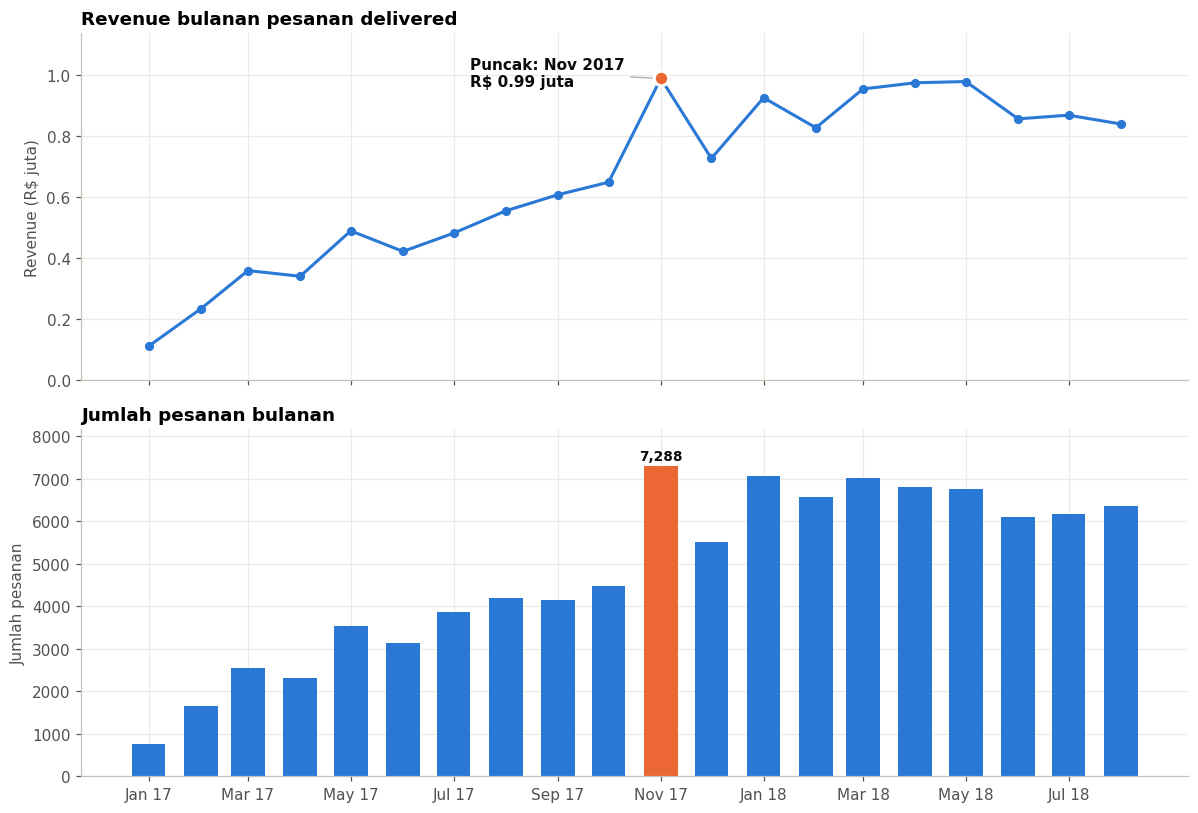

In [64]:
m = monthly.copy()
m['tanggal'] = pd.to_datetime(m['order_month'] + '-01')
pk = m['revenue'].idxmax()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)

ax1.plot(m['tanggal'], m['revenue'], color=BLUE, lw=2, marker='o', ms=5)
ax1.scatter(m.loc[pk, 'tanggal'], m.loc[pk, 'revenue'], s=90, color=ORANGE, zorder=5, edgecolor='white', linewidth=2)
ax1.annotate(f"Puncak: {m.loc[pk, 'tanggal']:%b %Y}\nR$ {m.loc[pk, 'revenue'] / 1e6:.2f} juta",
             (m.loc[pk, 'tanggal'], m.loc[pk, 'revenue']), xytext=(-125, -5), textcoords='offset points',
             color=INK, fontsize=10, fontweight='bold',
             arrowprops=dict(arrowstyle='-', color=GRAY))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1e6:.1f}'))
ax1.set_ylabel('Revenue (R$ juta)')
ax1.set_ylim(0, m['revenue'].max() * 1.15)
ax1.set_title('Revenue bulanan pesanan delivered')

ax2.bar(m['tanggal'], m['total_orders'], width=20,
        color=[ORANGE if i == m['total_orders'].idxmax() else BLUE for i in m.index])
ax2.set_ylabel('Jumlah pesanan')
ax2.set_title('Jumlah pesanan bulanan')
pk2 = m['total_orders'].idxmax()
ax2.text(m.loc[pk2, 'tanggal'], m.loc[pk2, 'total_orders'] + 150, f"{m.loc[pk2, 'total_orders']:,}",
         ha='center', color=INK, fontsize=9, fontweight='bold')
ax2.set_xticks(m['tanggal'][::2])
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax2.set_ylim(0, m['total_orders'].max() * 1.12)

fig.tight_layout()
plt.show()

### Pertanyaan 2: Kategori produk apa yang menjadi 10 besar revenue dan bagaimana review score-nya?

Panel kiri menunjukkan revenue (batang mulai dari nol). Panel kanan menunjukkan rata-rata review score; karena selisih antar-kategori kecil, dipakai *dot plot* dengan rentang sumbu yang dicantumkan jelas. Titik **oranye** = di bawah rata-rata keseluruhan, **biru** = sama atau di atas.

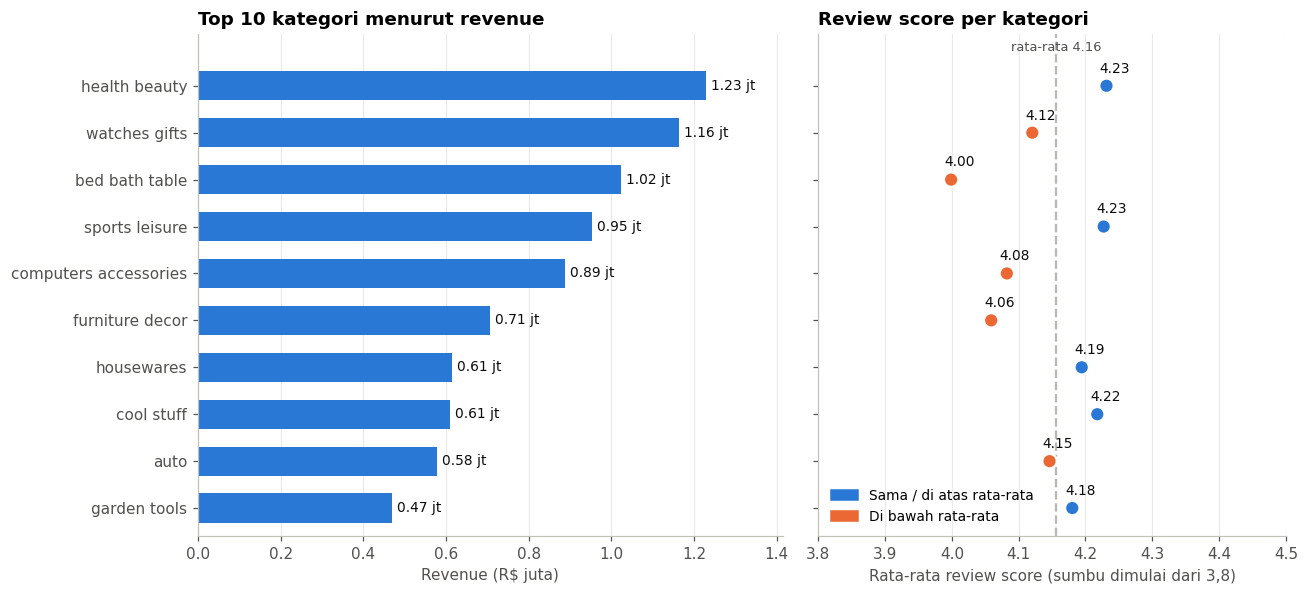

In [65]:
top10 = cat_summary.head(10).iloc[::-1].copy()      # dibalik agar peringkat 1 berada di atas
top10['nama'] = top10['product_category_name_english'].str.replace('_', ' ')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True, gridspec_kw={'width_ratios': [1.25, 1]})

ax1.barh(top10['nama'], top10['revenue'], color=BLUE, height=0.62)
for y, v in enumerate(top10['revenue']):
    ax1.text(v + top10['revenue'].max() * 0.01, y, f'{v / 1e6:.2f} jt', va='center', fontsize=9, color=INK)
ax1.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1e6:.1f}'))
ax1.set_xlabel('Revenue (R$ juta)')
ax1.set_xlim(0, top10['revenue'].max() * 1.15)
ax1.set_title('Top 10 kategori menurut revenue')
ax1.grid(axis='y', visible=False)

warna = np.where(top10['avg_review'] < avg_review_all, ORANGE, BLUE)
ax2.axvline(avg_review_all, color=GRAY, ls='--', lw=1.5)
ax2.scatter(top10['avg_review'], top10['nama'], s=90, c=warna, zorder=3, edgecolor='white', linewidth=1.5)
for y, v in enumerate(top10['avg_review']):
    ax2.text(v + 0.012, y + 0.28, f'{v:.2f}', fontsize=9, color=INK, ha='center')
ax2.text(avg_review_all, 9.75, f'rata-rata {avg_review_all:.2f}', color=INK_2, fontsize=8.5, ha='center')
ax2.set_xlim(3.8, 4.5)
ax2.set_ylim(-0.6, 10.1)
ax2.set_xlabel('Rata-rata review score (sumbu dimulai dari 3,8)')
ax2.set_title('Review score per kategori')
ax2.grid(axis='y', visible=False)
ax2.legend(handles=[mpatches.Patch(color=BLUE, label='Sama / di atas rata-rata'),
                    mpatches.Patch(color=ORANGE, label='Di bawah rata-rata')],
           loc='lower left', frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

### Pertanyaan 3: Seberapa besar keterlambatan menurunkan review score dan di state mana paling sering terlambat?

Panel kiri membandingkan rata-rata review score pada kelompok ketepatan pengiriman (hasil *binning*). Batang mulai dari nol agar perbedaan tidak dilebih-lebihkan. Panel kanan menampilkan 10 state (minimal 300 pesanan) dengan persentase keterlambatan tertinggi.

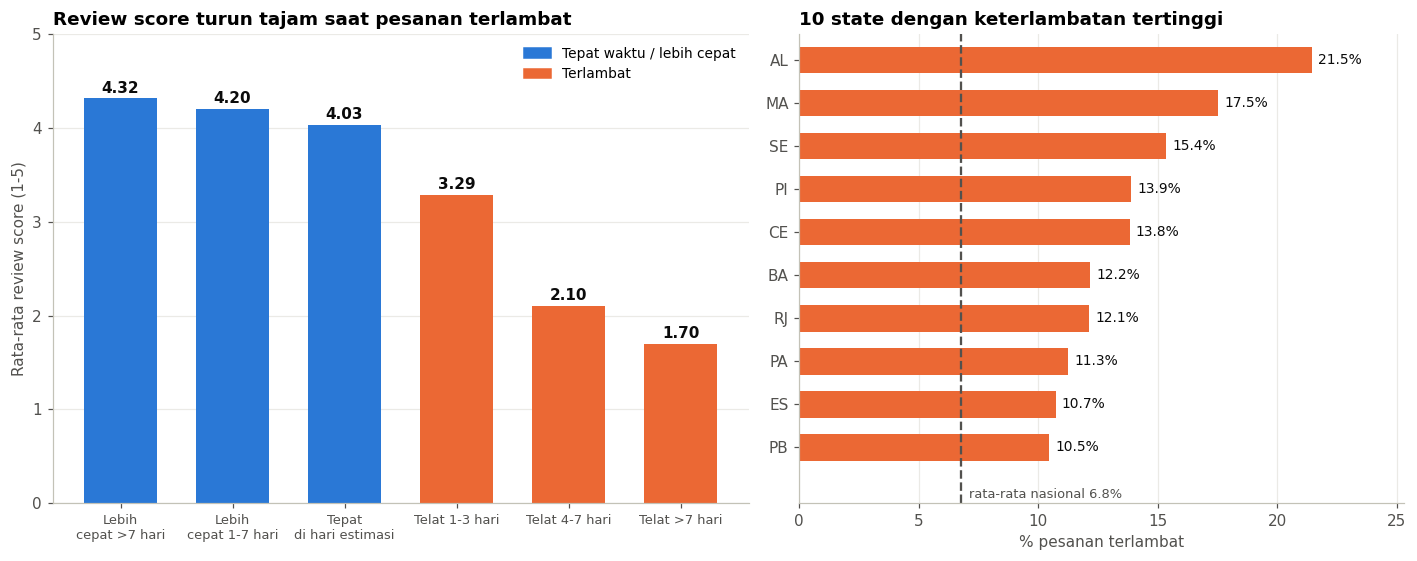

In [66]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.15, 1]})

# Panel kiri: review score per kelompok ketepatan
rb = review_bucket.copy()
warna_b = [BLUE if not str(l).startswith('Telat') else ORANGE for l in rb['delay_bucket']]
ax1.bar(range(len(rb)), rb['avg_review'], color=warna_b, width=0.65)
for i, v in enumerate(rb['avg_review']):
    ax1.text(i, v + 0.06, f'{v:.2f}', ha='center', fontsize=10, fontweight='bold', color=INK)
ax1.set_xticks(range(len(rb)))
ax1.set_xticklabels([l.replace(' ', '\n', 1) if len(l) > 14 else l for l in rb['delay_bucket'].astype(str)], fontsize=8.5)
ax1.set_ylim(0, 5)
ax1.set_ylabel('Rata-rata review score (1-5)')
ax1.set_title('Review score turun tajam saat pesanan terlambat')
ax1.grid(axis='x', visible=False)
ax1.legend(handles=[mpatches.Patch(color=BLUE, label='Tepat waktu / lebih cepat'),
                    mpatches.Patch(color=ORANGE, label='Terlambat')],
           loc='upper right', frameon=False, fontsize=9)

# Panel kanan: state dengan persentase terlambat tertinggi
t10 = state_late[state_late['total_orders'] >= 300].nlargest(10, 'late_rate').iloc[::-1]
ax2.barh(t10['customer_state'], t10['late_rate'], color=ORANGE, height=0.62)
for y, v in enumerate(t10['late_rate']):
    ax2.text(v + 0.25, y, f'{v:.1f}%', va='center', fontsize=9, color=INK)
ax2.axvline(late_nasional, color=INK_2, ls='--', lw=1.5)
ax2.text(late_nasional + 0.3, -0.95, f'rata-rata nasional {late_nasional:.1f}%', color=INK_2, fontsize=8.5, va='top')
ax2.set_xlim(0, t10['late_rate'].max() * 1.18)
ax2.set_ylim(-1.3, 9.6)
ax2.set_xlabel('% pesanan terlambat')
ax2.set_title('10 state dengan keterlambatan tertinggi')
ax2.grid(axis='y', visible=False)

fig.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** Revenue bulanan tumbuh hampir 9 kali lipat dari Jan 2017 (R$ 0,11 juta) ke puncak Nov 2017 (R$ 0,99 juta; 7.288 pesanan). Setelah Des 2017 turun 26,5%, pertumbuhan melandai di 2018 dan revenue turun dari R$ 0,98 juta (Mei 2018) ke R$ 0,84 juta (Agu 2018), sekitar -14%. Lonjakan akhir November sesuai dengan momen belanja Black Friday, namun dataset tidak memuat data kampanye sehingga dugaan ini perlu dikonfirmasi tim bisnis.
- **Pertanyaan 2:** Sepuluh kategori teratas menguasai 62,5% revenue. `health_beauty`, `sports_leisure` (keduanya 4,23), dan `cool_stuff` (4,22) punya review di atas rata-rata 4,16. Sebaliknya `bed_bath_table` (4,00), `furniture_decor` (4,06), `computers_accessories` (4,08), `watches_gifts` (4,12), dan `auto` (4,15) berada di bawah rata-rata. `bed_bath_table` paling mencolok: jumlah pesanan terbanyak (9.267) tetapi review terendah di antara 10 besar.
- **Pertanyaan 3:** Review score menurun seiring lamanya keterlambatan: 4,32 (lebih cepat >7 hari), 3,29 (telat 1-3 hari), 2,10 (telat 4-7 hari), dan 1,70 (telat >7 hari). Pesanan yang tiba tepat di hari estimasi (4,03) pun lebih rendah dari yang datang lebih cepat. Keterlambatan tertinggi ada di wilayah Timur Laut Brasil (AL, MA, SE, PI, CE) dan RJ.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan (tanpa *machine learning*) diterapkan:
1. **RFM Analysis + Manual Grouping**: mengelompokkan pelanggan berdasarkan perilaku belanja agar strategi retensi dapat disesuaikan per kelompok.
2. **Geospatial Analysis**: memetakan revenue dan persentase keterlambatan per state dan per kota memakai koordinat dari `geolocation_dataset.csv`, serta menganalisis pengaruh jarak penjual-pelanggan terhadap pengiriman.
3. **Binning**: membagi `delay_days` menjadi kelompok ketepatan pengiriman (Pertanyaan 3) dan `distance_km` menjadi kelompok jarak (Geospatial).

### RFM Analysis

**Tujuan:** mengelompokkan pelanggan (`customer_unique_id`) menurut tiga ukuran:
- **Recency (R):** jumlah hari sejak pembelian terakhir (semakin kecil semakin baik). Tanggal acuan = sehari setelah pesanan terakhir pada data.
- **Frequency (F):** jumlah pesanan unik pelanggan.
- **Monetary (M):** total pengeluaran barang (`price`) pelanggan.

**Manual grouping:** skor R dan M dibuat dengan membagi data menjadi 4 kuantil (*binning*, 4 = terbaik). Karena hampir semua pelanggan hanya membeli sekali, Frequency tidak dibagi kuantil tetapi dipakai sebagai aturan bisnis:

| Segmen | Aturan |
|---|---|
| **Repeat Customer** | Frequency >= 2 |
| **Big Spender (sekali beli)** | Frequency = 1 dan skor M = 4 |
| **Pelanggan Baru** | Frequency = 1, skor M < 4, skor R >= 3 (belanja relatif baru) |
| **Dorman / Berisiko Hilang** | Frequency = 1, skor M < 4, skor R <= 2 (sudah lama tidak belanja) |

In [67]:
tanggal_acuan = all_df['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)

rfm = (all_df.groupby('customer_unique_id')
       .agg(last_purchase=('order_purchase_timestamp', 'max'),
            frequency=('order_id', 'nunique'),
            monetary=('price', 'sum'))
       .reset_index())
rfm['recency'] = (tanggal_acuan - rfm['last_purchase'].dt.normalize()).dt.days

# Binning kuantil: skor 4 = terbaik (recency kecil, monetary besar)
rfm['r_score'] = pd.qcut(rfm['recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

def segmen(r):
    if r['frequency'] >= 2:
        return 'Repeat Customer'
    if r['m_score'] == 4:
        return 'Big Spender (sekali beli)'
    if r['r_score'] >= 3:
        return 'Pelanggan Baru'
    return 'Dorman / Berisiko Hilang'

rfm['segmen'] = rfm.apply(segmen, axis=1)

print(f'Tanggal acuan RFM: {tanggal_acuan:%d %b %Y} | jumlah pelanggan: {len(rfm):,}')
print('Distribusi frequency (% pelanggan):')
print((rfm['frequency'].clip(upper=3).value_counts(normalize=True).sort_index() * 100).round(1).rename({3: '3+'}).to_string())

urutan = ['Repeat Customer', 'Big Spender (sekali beli)', 'Pelanggan Baru', 'Dorman / Berisiko Hilang']
rfm_summary = (rfm.groupby('segmen')
               .agg(jumlah_pelanggan=('customer_unique_id', 'count'),
                    avg_recency=('recency', 'mean'),
                    avg_frequency=('frequency', 'mean'),
                    avg_monetary=('monetary', 'mean'),
                    total_monetary=('monetary', 'sum'))
               .reindex(urutan))
rfm_summary['persen_pelanggan'] = rfm_summary['jumlah_pelanggan'] / rfm_summary['jumlah_pelanggan'].sum() * 100
rfm_summary['persen_revenue'] = rfm_summary['total_monetary'] / rfm_summary['total_monetary'].sum() * 100
rfm_summary.round(1)

Tanggal acuan RFM: 30 Aug 2018 | jumlah pelanggan: 93,096
Distribusi frequency (% pelanggan):
frequency
1     97.0
2      2.8
3+     0.2


,jumlah_pelanggan,avg_recency,avg_frequency,avg_monetary,total_monetary,persen_pelanggan,persen_revenue
segmen,,,,,,,
Repeat Customer,2789,220.1,2.1,260.1,725355.0,3.0,5.5
Big Spender (sekali beli),21599,239.3,1.0,352.9,7623004.0,23.2,57.8
Pelanggan Baru,34409,112.3,1.0,71.1,2447249.9,37.0,18.6
Dorman / Berisiko Hilang,34299,362.7,1.0,69.5,2384169.0,36.8,18.1


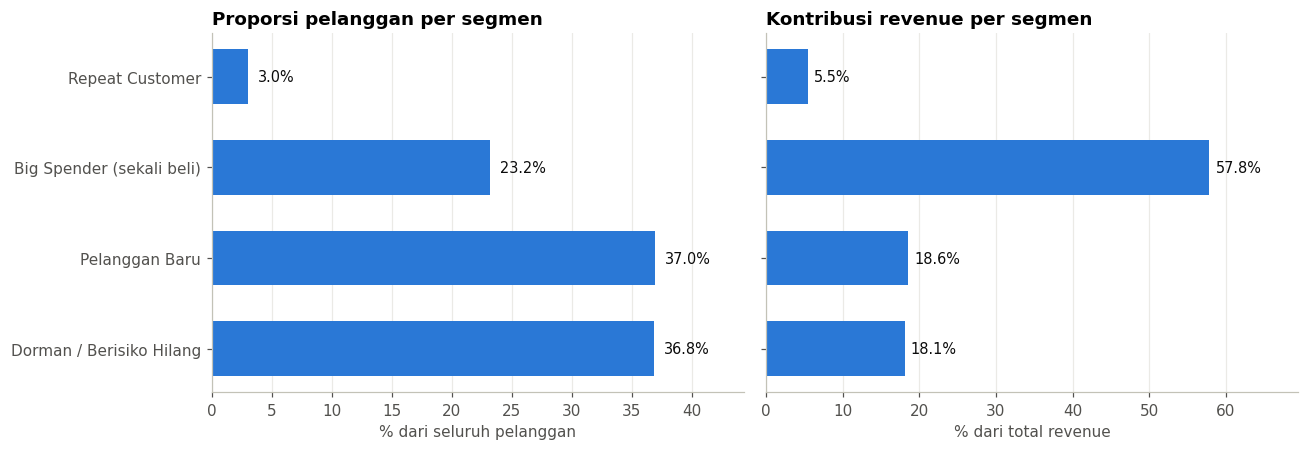

In [68]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
rs = rfm_summary.iloc[::-1]

ax1.barh(rs.index, rs['persen_pelanggan'], color=BLUE, height=0.6)
for y, v in enumerate(rs['persen_pelanggan']):
    ax1.text(v + 0.8, y, f'{v:.1f}%', va='center', fontsize=9.5, color=INK)
ax1.set_xlim(0, rs['persen_pelanggan'].max() * 1.2)
ax1.set_xlabel('% dari seluruh pelanggan')
ax1.set_title('Proporsi pelanggan per segmen')
ax1.grid(axis='y', visible=False)

ax2.barh(rs.index, rs['persen_revenue'], color=BLUE, height=0.6)
for y, v in enumerate(rs['persen_revenue']):
    ax2.text(v + 0.8, y, f'{v:.1f}%', va='center', fontsize=9.5, color=INK)
ax2.set_xlim(0, rs['persen_revenue'].max() * 1.2)
ax2.set_xlabel('% dari total revenue')
ax2.set_title('Kontribusi revenue per segmen')
ax2.grid(axis='y', visible=False)

fig.tight_layout()
plt.show()

**Insight:**
- Sebanyak **97,0%** pelanggan hanya membeli satu kali. Segmen *Repeat Customer* hanya 3,0% pelanggan (2.789 orang) dan menyumbang 5,5% revenue, jadi retensi menjadi peluang besar.
- Segmen *Big Spender (sekali beli)* hanya 23,2% pelanggan (21.599 orang) tetapi menyumbang **57,8% revenue** dengan rata-rata belanja R$ 352,9 per pelanggan.
- *Pelanggan Baru* (37,0%) dan *Dorman / Berisiko Hilang* (36,8%) masing-masing menyumbang sekitar 18% revenue dengan rata-rata belanja sekitar R$ 70. Rata-rata recency segmen dorman 362,7 hari, yaitu hampir setahun tanpa pembelian.

### Geospatial Analysis

**Tujuan:** (1) melihat sebaran revenue dan keterlambatan pengiriman per *state* dan per *kota* di Brasil, dan (2) memeriksa apakah **jarak** penjual ke pelanggan menjelaskan keterlambatan dan lama pengiriman.

Koordinat berasal dari `geolocation_dataset.csv` (median per kode pos). Titik tengah *state* dihitung dari sebaran koordinat pelanggan di state tersebut, bukan ditebak. Ukuran lingkaran = revenue, warna **oranye** = persentase terlambat di atas rata-rata nasional, **biru** = di bawah/sama.

In [69]:
# Titik tengah state = median koordinat pelanggan di state tersebut (berasal dari data geolocation)
pusat_state = (all_df.dropna(subset=['customer_lat'])
               .groupby('customer_state')
               .agg(lat=('customer_lat', 'median'), lon=('customer_lng', 'median')))

geo = (all_df.groupby('customer_state')
       .agg(revenue=('price', 'sum'), total_orders=('order_id', 'nunique'),
            pelanggan=('customer_unique_id', 'nunique'))
       .join(state_late.set_index('customer_state')[['late_rate', 'avg_delivery_days', 'avg_review']])
       .join(pusat_state)
       .reset_index())
geo['revenue_share'] = geo['revenue'] / geo['revenue'].sum() * 100
geo = geo.sort_values('revenue', ascending=False).reset_index(drop=True)

print('State tanpa koordinat:', geo['lat'].isna().sum())
print('Top 5 state menurut revenue, dan kontribusi kumulatifnya:', round(geo['revenue_share'].head(5).sum(), 1), '%')
display(geo.head(8).round(2))

# Peta interaktif level state
peta = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles='CartoDB positron')
for _, r in geo.iterrows():
    warna = ORANGE if r['late_rate'] > late_nasional else BLUE
    folium.CircleMarker(
        location=[r['lat'], r['lon']],
        radius=5 + (r['revenue'] / geo['revenue'].max()) ** 0.5 * 28,
        color=warna, weight=1.5, fill=True, fill_color=warna, fill_opacity=0.55,
        tooltip=f"{r['customer_state']}: R$ {r['revenue'] / 1e6:.2f} jt | terlambat {r['late_rate']:.1f}%",
        popup=folium.Popup(f"<b>{r['customer_state']}</b><br>Revenue: R$ {r['revenue']:,.0f}<br>Pesanan: {r['total_orders']:,}<br>"
                           f"% terlambat: {r['late_rate']:.1f}%<br>Rata-rata review: {r['avg_review']:.2f}", max_width=220),
    ).add_to(peta)
peta

State tanpa koordinat: 0
Top 5 state menurut revenue, dan kontribusi kumulatifnya: 73.9 %


,customer_state,revenue,total_orders,pelanggan,late_rate,avg_delivery_days,avg_review,lat,lon,revenue_share
0,SP,5054516.95,40399,39058,4.50,8.74,4.25,-23.51,-46.69,38.35
1,RJ,1751433.85,12310,11879,12.14,15.30,3.97,-22.89,-43.25,13.29
2,MG,1548206.88,11319,10969,4.59,11.98,4.19,-19.93,-43.98,11.75
3,RS,726194.92,5327,5150,6.10,15.29,4.19,-29.89,-51.23,5.51
4,PR,664048.00,4903,4750,4.06,11.97,4.24,-25.39,-50.23,5.04
5,SC,504774.07,3537,3441,8.23,14.95,4.13,-27.15,-49.01,3.83
6,BA,493339.26,3253,3155,12.17,19.33,3.93,-12.95,-38.76,3.74
7,DF,295454.64,2074,2013,5.69,12.94,4.13,-15.82,-47.95,2.24


#### Peta level kota

In [70]:
# Kota dengan minimal 200 pesanan (kota kecil dibuang agar persentase terlambat stabil)
MIN_PESANAN_KOTA = 200
kota_peta = kota[kota['total_orders'] >= MIN_PESANAN_KOTA].dropna(subset=['lat', 'lon']).copy()
kota_peta['nama'] = kota_peta['customer_city'].str.title().str.replace(' De ', ' de ', regex=False)
print(f'Kota di peta: {len(kota_peta)} | menyumbang {kota_peta["revenue_share"].sum():.1f}% revenue')

peta_kota = folium.Map(location=[-18.5, -47.0], zoom_start=5, tiles='CartoDB positron')
for _, r in kota_peta.iterrows():
    warna = ORANGE if r['late_rate'] > late_nasional else BLUE
    folium.CircleMarker(
        location=[r['lat'], r['lon']],
        radius=4 + (r['revenue'] / kota_peta['revenue'].max()) ** 0.5 * 24,
        color=warna, weight=1.2, fill=True, fill_color=warna, fill_opacity=0.55,
        tooltip=f"{r['nama']} ({r['customer_state']}): R$ {r['revenue'] / 1e3:,.0f} rb | terlambat {r['late_rate']:.1f}%",
        popup=folium.Popup(f"<b>{r['nama']} - {r['customer_state']}</b><br>Revenue: R$ {r['revenue']:,.0f}<br>Pesanan: {r['total_orders']:,}<br>"
                           f"% terlambat: {r['late_rate']:.1f}%<br>Rata-rata review: {r['avg_review']:.2f}", max_width=240),
    ).add_to(peta_kota)
peta_kota

Kota di peta: 68 | menyumbang 55.5% revenue


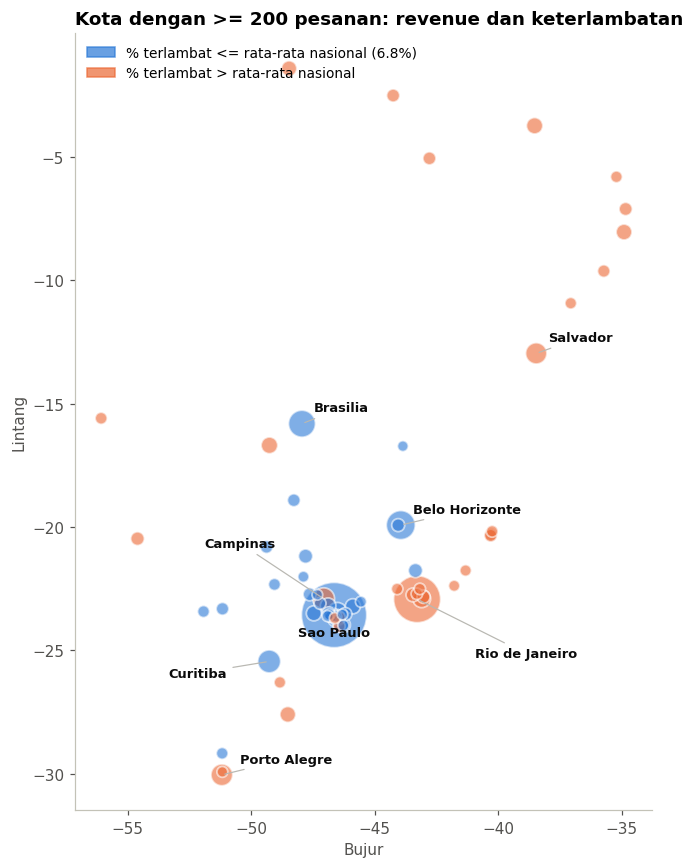

In [71]:
# Versi statis peta kota (tetap terlihat walau widget interaktif tidak dimuat)
fig, ax = plt.subplots(figsize=(8.5, 8))
warna = np.where(kota_peta['late_rate'] > late_nasional, ORANGE, BLUE)
ax.scatter(kota_peta['lon'], kota_peta['lat'], s=(kota_peta['revenue'] / kota_peta['revenue'].max()) * 1800 + 25,
           c=warna, alpha=0.6, edgecolor='white', linewidth=1.2)
# Posisi label diatur manual agar kota yang berdekatan (Sao Paulo, Campinas, Rio) tidak saling menimpa
geser_label = {'Sao Paulo': (0, -14), 'Campinas': (-78, 34), 'Rio de Janeiro': (38, -38),
               'Porto Alegre': (12, 8), 'Curitiba': (-66, -10)}
for _, r in kota_peta.head(8).iterrows():
    sp = r['nama'] == 'Sao Paulo'          # label Sao Paulo ditaruh di dalam lingkarannya yang besar
    ax.annotate(r['nama'], (r['lon'], r['lat']), xytext=geser_label.get(r['nama'], (8, 8)), textcoords='offset points',
                fontsize=8.5, fontweight='bold', color=INK, ha='center' if sp else 'left',
                arrowprops=None if sp else dict(arrowstyle='-', color=GRAY, lw=0.8))
ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang')
ax.set_title(f'Kota dengan >= {MIN_PESANAN_KOTA} pesanan: revenue dan keterlambatan')
ax.legend(handles=[mpatches.Patch(color=BLUE, alpha=0.7, label=f'% terlambat <= rata-rata nasional ({late_nasional:.1f}%)'),
                   mpatches.Patch(color=ORANGE, alpha=0.7, label='% terlambat > rata-rata nasional')],
          loc='upper left', frameon=False, fontsize=9)
ax.grid(False)
ax.set_aspect('equal')
fig.tight_layout()
plt.show()

#### Pengaruh jarak penjual-pelanggan terhadap pengiriman

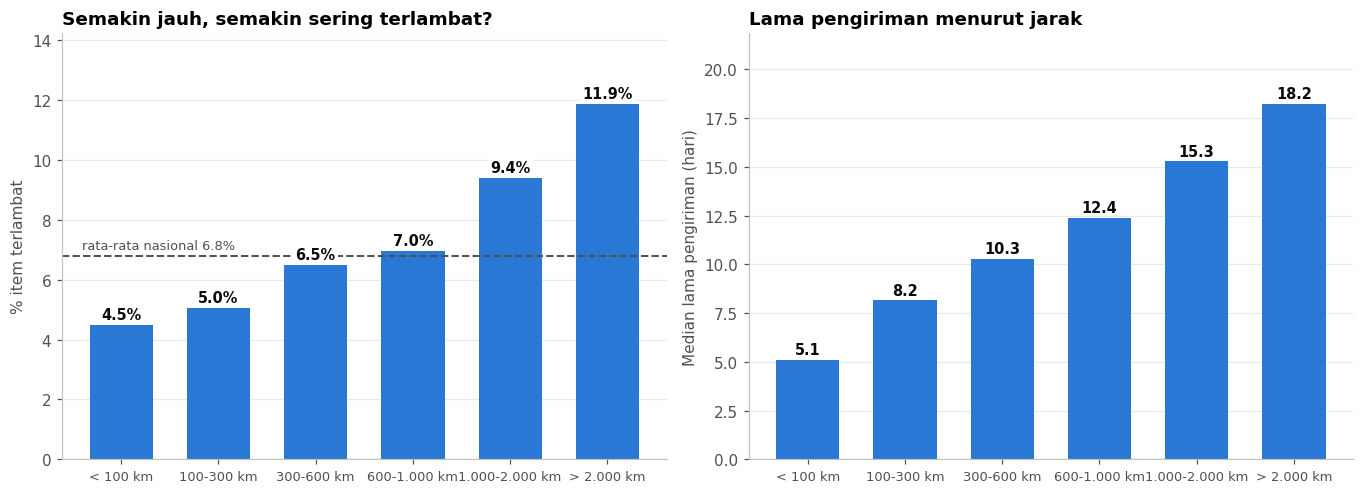

In [72]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
x = range(len(jarak))

ax1.bar(x, jarak['persen_terlambat'], color=BLUE, width=0.65)
for i, v in enumerate(jarak['persen_terlambat']):
    ax1.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=9.5, fontweight='bold', color=INK, zorder=5,
             bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ax1.axhline(late_nasional, color=INK_2, ls='--', lw=1.3)
ax1.text(-0.4, late_nasional + 0.25, f'rata-rata nasional {late_nasional:.1f}%', color=INK_2, fontsize=8.5, ha='left')
ax1.set_xticks(list(x)); ax1.set_xticklabels(jarak['jarak_kelompok'].astype(str), fontsize=8.5)
ax1.set_ylim(0, jarak['persen_terlambat'].max() * 1.2)
ax1.set_ylabel('% item terlambat')
ax1.set_title('Semakin jauh, semakin sering terlambat?')
ax1.grid(axis='x', visible=False)

ax2.bar(x, jarak['median_hari_kirim'], color=BLUE, width=0.65)
for i, v in enumerate(jarak['median_hari_kirim']):
    ax2.text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=9.5, fontweight='bold', color=INK)
ax2.set_xticks(list(x)); ax2.set_xticklabels(jarak['jarak_kelompok'].astype(str), fontsize=8.5)
ax2.set_ylim(0, jarak['median_hari_kirim'].max() * 1.2)
ax2.set_ylabel('Median lama pengiriman (hari)')
ax2.set_title('Lama pengiriman menurut jarak')
ax2.grid(axis='x', visible=False)

fig.tight_layout()
plt.show()

#### Apakah jarak saja cukup menjelaskan keterlambatan?

Jarak yang lebih jauh dapat menjelaskan sebagian keterlambatan, tetapi belum tentu semuanya. Pengecekan berikut membandingkan persentase terlambat pada **kelompok jarak yang sama** antara RJ, SP, dan state lain, serta membandingkan wilayah Timur Laut (*Nordeste*) dengan wilayah lain.

In [73]:
data_jarak = all_df.dropna(subset=['distance_km']).copy()
data_jarak['kelompok_state'] = np.where(data_jarak['customer_state'] == 'RJ', 'RJ',
                                        np.where(data_jarak['customer_state'] == 'SP', 'SP', 'State lain'))

print('% item terlambat pada kelompok jarak yang sama:')
display((data_jarak.pivot_table(index='jarak_kelompok', columns='kelompok_state', values='is_late',
                                aggfunc='mean', observed=True) * 100).round(1))
print('Jumlah item per sel (sel dengan item sedikit kurang dapat diandalkan):')
display(data_jarak.pivot_table(index='jarak_kelompok', columns='kelompok_state', values='is_late',
                               aggfunc='count', observed=True))

timur_laut = ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE']
data_jarak['wilayah'] = np.where(data_jarak['customer_state'].isin(timur_laut), 'Timur Laut (9 state)', 'Wilayah lain')
display(data_jarak.groupby('wilayah')
        .agg(median_jarak_km=('distance_km', 'median'), persen_terlambat=('is_late', lambda s: s.mean() * 100),
             avg_review=('review_score', 'mean'))
        .round(1))

% item terlambat pada kelompok jarak yang sama:


kelompok_state,RJ,SP,State lain
jarak_kelompok,,,
< 100 km,5.1,4.5,3.1
100-300 km,9.4,4.7,5.0
300-600 km,12.6,4.1,5.2
600-1.000 km,12.5,3.2,6.5
1.000-2.000 km,9.2,3.0,9.6
> 2.000 km,5.4,11.6,11.9


Jumlah item per sel (sel dengan item sedikit kurang dapat diandalkan):


kelompok_state,RJ,SP,State lain
jarak_kelompok,,,
< 100 km,919,18222,1270
100-300 km,1049,11333,2891
300-600 km,8420,13760,13854
600-1.000 km,2936,2377,15115
1.000-2.000 km,661,266,10053
> 2.000 km,56,267,5886


,median_jarak_km,persen_terlambat,avg_review
wilayah,,,
Timur Laut (9 state),1877.4,12.6,3.9
Wilayah lain,385.6,6.0,4.1


**Insight:**
- Lima state teratas (SP 38,4%, RJ 13,3%, MG 11,8%, RS 5,5%, PR 5,0%) menyumbang **73,9% revenue**. Peta level kota menunjukkan konsentrasi yang sama: 68 kota dengan minimal 200 pesanan menyumbang 55,5% revenue, dengan lingkaran terbesar di sekitar Sao Paulo, Rio de Janeiro, dan Belo Horizonte.
- Lingkaran oranye (terlambat di atas rata-rata nasional 6,8%) mengelompok di Timur Laut Brasil dan di sekitar Rio de Janeiro, sedangkan kota-kota di sekitar Sao Paulo, Curitiba, Belo Horizonte, dan Brasilia umumnya berwarna biru. Enam state Timur Laut (AL, MA, SE, PI, CE, BA) punya rata-rata review hanya 3,83-3,99.
- SP, pasar terbesar sekaligus lokasi sebagian besar penjual (1.849 dari 3.095 penjual), terlambat 4,5% dengan review 4,25, jauh di bawah rata-rata nasional. Hanya PR yang sedikit lebih rendah (4,1%).
- **Jarak menjelaskan sebagian besar keterlambatan di Timur Laut.** Median jarak penjual ke pelanggan di 9 state Timur Laut adalah 1.877 km, jauh lebih tinggi dibanding 386 km di wilayah lain. Persentase terlambatnya 12,6% vs 6,0%, dan review 3,9 vs 4,1. Penyebabnya lebih bersifat struktural (penjual jauh dari pembeli).
- **Jarak tidak menjelaskan keterlambatan di RJ.** Pada kelompok jarak yang sama, RJ terlambat 9,4% (100-300 km), 12,6% (300-600 km), dan 12,5% (600-1.000 km), sedangkan SP hanya 4,7%, 4,1%, dan 3,2%, dan state lain 5,0%, 5,2%, dan 6,5%. Sekitar 88% item pesanan RJ berasal dari penjual berjarak 100-1.000 km, jadi RJ tidak berada di posisi yang terlalu jauh. Kemungkinan penyebabnya ada di sisi pengiriman lokal, tetapi dataset tidak memuat alasannya sehingga perlu dikonfirmasi tim logistik. Sel dengan item sedikit (misalnya RJ di atas 2.000 km hanya 56 item) tidak dijadikan dasar kesimpulan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue dan jumlah pesanan tumbuh pesat sepanjang 2017 (revenue Jan 2017 R$ 0,11 juta menjadi R$ 0,99 juta di Nov 2017, bulan puncak dengan 7.288 pesanan dan pertumbuhan MoM +52,4%), kemudian mendatar di 2018 pada kisaran R$ 0,83-0,98 juta per bulan dan melemah sekitar 14% dari Mei ke Agustus 2018.
- **Conclusion pertanyaan 2:** Sepuluh kategori teratas menyumbang 62,5% revenue, dipimpin `health_beauty` (R$ 1,23 juta), `watches_gifts` (R$ 1,16 juta), dan `bed_bath_table` (R$ 1,02 juta). Lima dari sepuluh kategori tersebut memiliki review di bawah rata-rata keseluruhan (4,16), terutama `bed_bath_table` (4,00) dan `furniture_decor` (4,06), sementara `health_beauty` dan `sports_leisure` kuat di revenue sekaligus review (4,23).
- **Conclusion pertanyaan 3:** Keterlambatan sangat berkaitan dengan kepuasan pelanggan: rata-rata review 2,27 untuk pesanan terlambat vs 4,29 untuk yang tepat waktu, dan semakin lama telat semakin rendah (1,70 untuk telat >7 hari). Persentase terlambat tertinggi ada di AL (21,5%), MA (17,5%), dan SE (15,4%), sedangkan RJ (12,1%) paling kritis karena volumenya besar. Analisis geospasial menunjukkan jarak penjual-pelanggan menjelaskan sebagian besar keterlambatan di Timur Laut (median jarak 1.877 km; terlambat 12,6% vs 6,0% di wilayah lain), tetapi tidak menjelaskan RJ (terlambat 12,6% pada jarak 300-600 km vs 4,1% di SP). Analisis lanjutan juga menunjukkan 97% pelanggan hanya membeli sekali dan 23,2% pelanggan *Big Spender* menyumbang 57,8% revenue.

**Rekomendasi Action Item:**
- **Perencanaan musiman:** siapkan stok, gudang, dan kapasitas kurir sebelum November (periode puncak seperti Nov 2017), dan rancang kampanye khusus untuk bulan-bulan yang melemah (Juni-Agustus). Konfirmasi dulu apakah lonjakan Nov 2017 berasal dari kampanye tertentu.
- **Prioritas kategori:** dorong promosi untuk `health_beauty`, `sports_leisure`, dan `cool_stuff` yang kuat di revenue dan review. Lakukan audit kualitas penjual, deskripsi produk, dan pengemasan pada `bed_bath_table`, `furniture_decor`, dan `computers_accessories`, serta selidiki penyebab review rendah `office_furniture` (3,65).
- **Perbaikan logistik:** untuk Timur Laut (AL, MA, SE, PI, CE, BA), masalah utamanya jarak (median 1.877 km), jadi dorong penjual atau stok lokal ke wilayah itu atau tambah gudang regional, dan revisi estimasi pengiriman agar lebih realistis. Untuk RJ, jarak tidak menjelaskan keterlambatan, sehingga telusuri kinerja kurir dan pengiriman lokal di sana bersama tim logistik. Dorong juga penjual dari state yang sama dengan pembeli karena pengiriman antar-state lebih lambat dan lebih sering terlambat.
- **Komunikasi proaktif:** kirim notifikasi dan kompensasi (misalnya voucher) otomatis begitu pesanan diprediksi telat, karena review turun tajam sejak keterlambatan 1-3 hari.
- **Retensi pelanggan:** buat voucher reaktivasi untuk segmen *Dorman*, program loyalitas khusus *Big Spender*, dan rangsang pembelian kedua bagi *Pelanggan Baru* (misalnya penawaran cross-sell dalam 90 hari setelah pembelian pertama).